# Horvitz-Thompson Exposure Contrasts

## Estimating the contrast between exposure means

For exposure $d\in\{0,1\}$, let $Y_i(d)$ be unit $i$'s potential outcome and let $\pi_i(d)=\Pr\{D_i(Z)=d\}$ be its known marginal exposure probability. The Horvitz-Thompson mean is

$$
\widehat\mu(d)=\frac{1}{N}\sum_{i=1}^{N}\frac{\mathbf 1\{D_i=d\}Y_i}{\pi_i(d)}.
$$

Here, $N$ is the number of units, $D_i$ is the realized exposure, and $Y_i=Y_i(D_i)$ is the observed outcome. The mean exposure contrast is

$$
\widehat\tau_{1,0}=\widehat\mu(1)-\widehat\mu(0).
$$

Known positive probabilities make the two weighted means unbiased under the declared randomization design. A variance calculation would also require joint exposure probabilities, which are not supplied to the released calculation.

Row,Unit,Outcome with no exposed neighbor,Outcome with an exposed neighbor,Exposure effect
,Int64,Float64,Float64,Float64
1,0,1.0,2.0,1.0
2,1,3.0,7.0,4.0
3,2,2.0,1.0,-1.0


Row,Assignment,Exposure,First mean,Second mean,Contrast
,String,String,Float64,Float64,Float64
1,000,000,0.0,8.0,-8.0
2,001,110,4.0,2.66667,1.33333
3,010,101,1.33333,4.0,-2.66667
4,011,111,4.44444,0.0,4.44444
5,100,011,3.55556,1.33333,2.22222
6,101,111,4.44444,0.0,4.44444
7,110,111,4.44444,0.0,4.44444
8,111,111,4.44444,0.0,4.44444


Row,Quantity,Value
,String,Real
1,Assignments,8
2,Known average exposure effect,1.33333
3,Average released contrast,1.33333
4,Absolute difference,2.22045e-16


Row,Unit,Exposure,Observed outcome,Unit contribution
,Int64,Int64,Float64,Float64
1,0,1,2.0,2.66667
2,1,1,7.0,9.33333
3,2,1,1.0,1.33333


Row,Returned quantity,Available
,String,String
1,First exposure mean,Yes
2,Second exposure mean,Yes
3,Mean contrast,Yes
4,Unit contributions,Yes
5,Variance,No
6,Confidence interval,No


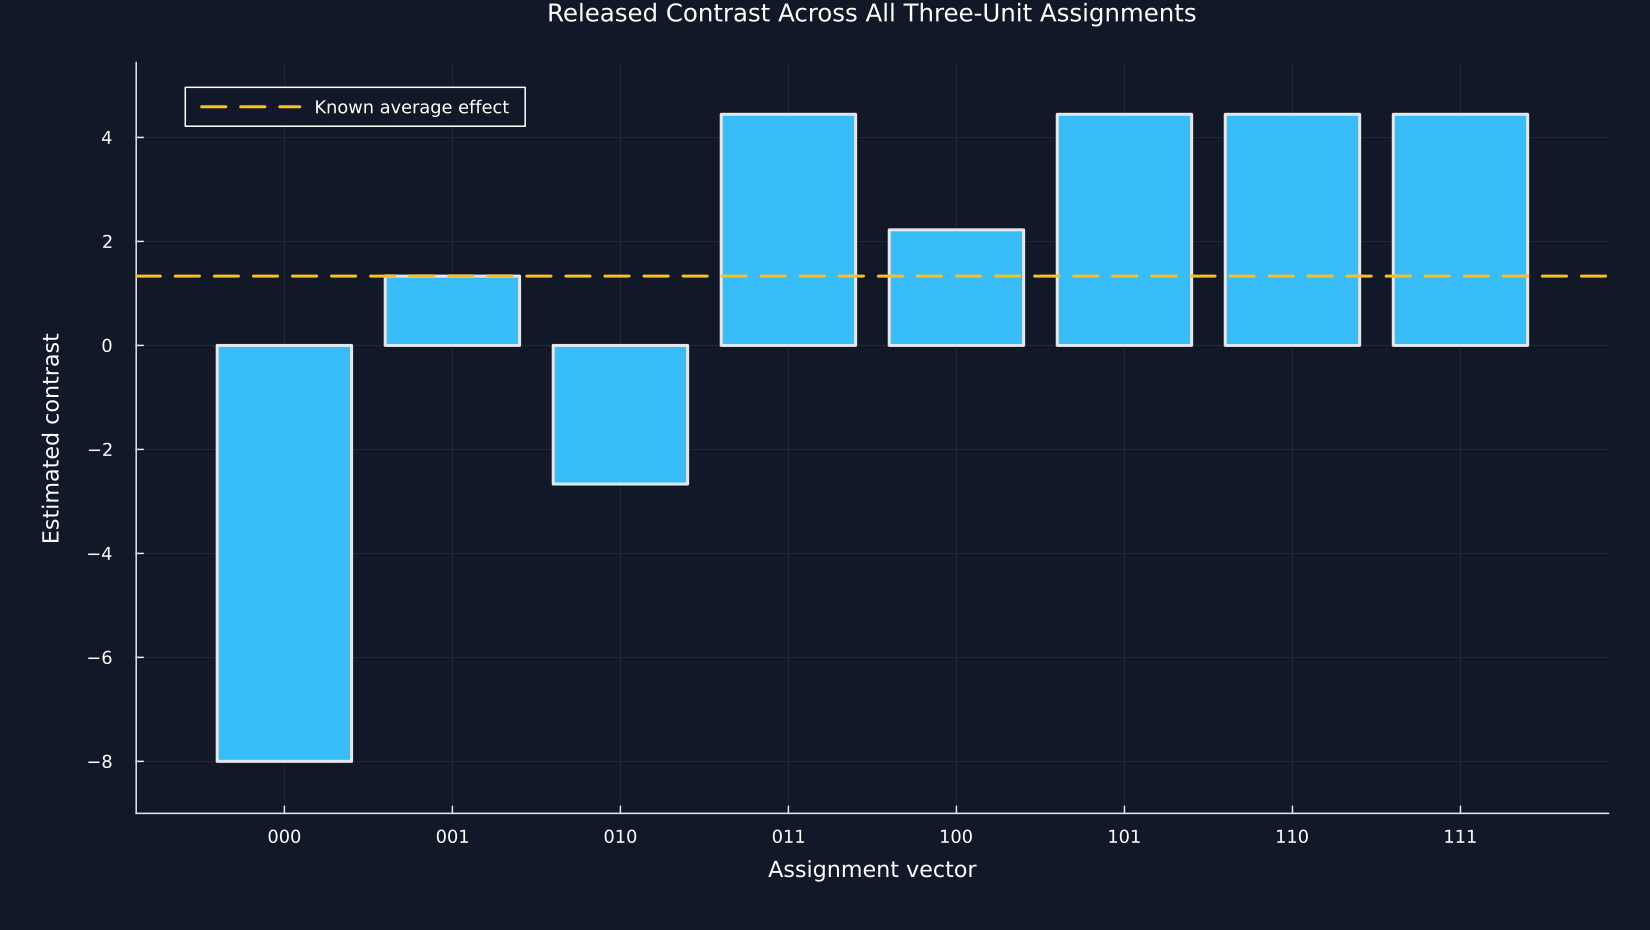

In [1]:
using RiskLabAI, Random, Statistics, LinearAlgebra, DataFrames, Dates, Plots
include(joinpath("..", "support", "BookSupport.jl"))
using .BookSupport
import .BookSupport: palette
@assert pkgversion(RiskLabAI) == v"1.1.0"
configure_plots!()
paths = output_paths("07_network_interference");
using CSV, TOML, Printf
using RiskLabAI.CausalFactorAnalysis: exposure_mean_contrast
include(joinpath("..","support","CausalNotebookTools.jl"))
using .CausalNotebookTools
include(joinpath("..","support","BookCausalStudy.jl"))
using .BookCausalStudy
import .BookCausalStudy: frame
include(joinpath("..","support","BookIdentificationStudy.jl"))
using .BookIdentificationStudy: PrimitiveStore, normal_block
include(joinpath("..","support","BookNetworkStudy.jl"))
using .BookNetworkStudy
default(left_margin=10Plots.mm,bottom_margin=10Plots.mm)
store=PrimitiveStore(joinpath("..","data","chapter07_random_inputs"),"network")
captions=Dict("mapping_public_provenance"=>"Provenance of the public returns used only to fix a topology.","mapping_public_industries"=>"Selected public industries and descriptive topology degrees.","mapping_public_edges"=>"Edges in the fixed public correlation topology.","mapping_public_graph_summary"=>"Summary of the fixed public correlation topology.","mapping_scope_ledger"=>"Roles and limits of the public and generated inputs.","mapping_definition"=>"Objects in the neighbor-exposure mapping.","mapping_public_assignment"=>"One generated assignment on the fixed public topology.","mapping_public_probabilities"=>"Exact marginal exposure probabilities under independent assignment.","mapping_assignment_contract"=>"Declared generated assignment on the fixed public topology.","mapping_probability_check"=>"Enumeration check for marginal neighbor-exposure probabilities.","mapping_section_summary"=>"Summary of the fixed topology and exposure mapping.","ht_exact_potential_outcomes"=>"Potential outcomes in the released three-unit exact design.","ht_exact_assignments"=>"All assignments in the released three-unit exact design.","ht_exact_summary"=>"Exact randomization expectation for the released exposure contrast.","ht_exact_contributions"=>"Unit contributions for one exact-design assignment.","ht_returned_fields"=>"Quantities returned by the released exposure calculation.","ht_graph_enumeration"=>"Exact exposure-contrast enumeration across four small graphs.","ht_public_generated_design"=>"Generated potential-outcome design on the fixed public topology.","ht_public_exact_summary"=>"Exact design expectations on the fixed public topology.","ht_public_repeated_summary"=>"Repeated generated assignments on the fixed public topology.","ht_public_quantiles"=>"Finite-sample distributions under repeated generated assignments.","ht_public_contributions"=>"Unit contributions under one generated public-topology assignment.","ht_invalid_input_checks"=>"Plain-language checks for invalid exposure calculations.","scope_probability_grid"=>"Exposure probabilities across degree and assignment probability.","scope_probability_grid_selected"=>"Selected positivity cases for the neighbor-exposure rule.","scope_simulation_grid"=>"Finite-sample variation across regular graph designs.","scope_simulation_grid_book"=>"Selected finite-sample results across regular graph designs.","scope_rule_comparison"=>"Comparison of one-neighbor and two-neighbor exposure rules.","scope_public_density_sweep"=>"Generated exposure calculations across descriptive public topologies.","scope_public_density_sweep_book"=>"Readable density and exposure-rarity comparison.","scope_financial_network_context"=>"Permitted interpretation of the financial network comparison.","scope_claim_boundary"=>"Scientific boundaries for the network calculations.","scope_section_summary"=>"Summary of density, positivity, and scope results.")
function table(values,name)
    shown=copy(values)
    for column in names(shown)
        if all(value->value isa Bool,shown[!,column])
            shown[!,column]=ifelse.(shown[!,column],"Pass","Fail")
        end
    end
    save_table(shown,paths,name;caption=captions[name],label="tab:cim7-"*replace(name,"_"=>"-"))
    return nothing
end
assignments=all_assignments(3)
ring_three=ring_graph(3)
potential=[1. 2.;3. 7.;2. 1.]
probabilities=repeat([.25 .75],3)
exact_rows=[]
for assignment in assignments
    exposure=exposure_labels(ring_three,assignment)
    outcome=[potential[unit,exposure[unit]+1] for unit in 1:3]
    result=exposure_result(outcome,exposure,probabilities)
    push!(exact_rows,(join(assignment),join(exposure),result.first_mean,result.second_mean,result.contrast))
end
exact_assignments=frame(["Assignment","Exposure","First mean","Second mean","Contrast"],exact_rows)
truth=mean(potential[:,2]-potential[:,1])
exact_average=mean(exact_assignments.Contrast)
@assert isapprox(exact_average,truth)
potential_table=DataFrame("Unit"=>0:2,"Outcome with no exposed neighbor"=>potential[:,1],"Outcome with an exposed neighbor"=>potential[:,2],"Exposure effect"=>potential[:,2]-potential[:,1])
table(potential_table,"ht_exact_potential_outcomes")
table(exact_assignments,"ht_exact_assignments")
exact_summary=frame(["Quantity","Value"],[("Assignments",8),("Known average exposure effect",truth),("Average released contrast",exact_average),("Absolute difference",abs(exact_average-truth))])
table(exact_summary,"ht_exact_summary")
example_assignment=assignments[6]
example_exposure=exposure_labels(ring_three,example_assignment)
example_outcome=[potential[unit,example_exposure[unit]+1] for unit in 1:3]
example_result=exposure_result(example_outcome,example_exposure,probabilities)
contribution_table=DataFrame("Unit"=>0:2,"Exposure"=>example_exposure,"Observed outcome"=>example_outcome,"Unit contribution"=>example_result.unit_contributions)
table(contribution_table,"ht_exact_contributions")
returned_fields = frame(["Returned quantity","Available"],[["First exposure mean","Yes"],["Second exposure mean","Yes"],["Mean contrast","Yes"],["Unit contributions","Yes"],["Variance","No"],["Confidence interval","No"]])
table(returned_fields,"ht_returned_fields")
save_data(exact_assignments,paths,"ht_exact_assignments")
figure=bar(1:8,exact_assignments.Contrast;color=palette.cyan,label="",xticks=(1:8,exact_assignments.Assignment),xlabel="Assignment vector",ylabel="Estimated contrast",title="Released Contrast Across All Three-Unit Assignments",size=(1100,620),ylims=(minimum(exact_assignments.Contrast)-1,maximum(exact_assignments.Contrast)+1))
hline!(figure,[truth];color=palette.amber,linewidth=2,linestyle=:dash,label="Known average effect")
save_figure(figure,paths,"ht_exact_assignments")


## Exact Enumeration Across Four Graphs

For a graph $G$ and independent assignment probability $p$, let $\mathcal Z$ contain all $2^N$ assignments. The design expectation is

$$
\mathbb E_Z[\widehat\tau_{1,0}]
=\sum_{z\in\mathcal Z}\Pr(Z=z)\widehat\tau_{1,0}(z).
$$

The factor $\Pr(Z=z)$ is determined before outcomes are observed. Exact enumeration checks the mean contrast for line, ring, star, and complete graphs without relying on a large-sample approximation.

Row,Graph,Edges,Minimum degree,Maximum degree,Known average effect,Exact expected estimate,Absolute error,Minimum assignment estimate,Maximum assignment estimate
,String,Float64,Int64,Int64,Float64,Float64,Float64,Float64,Float64
1,Line,3.0,1,2,0.65,0.65,0.0,-3.47929,5.39394
2,Ring,4.0,2,2,0.7,0.7,5.55112e-16,-4.49704,4.50216
3,Star,3.0,1,3,0.65,0.65,2.22045e-16,-3.69117,5.85912
4,Complete,6.0,3,3,0.8,0.8,1.33227e-15,-8.01092,4.13579


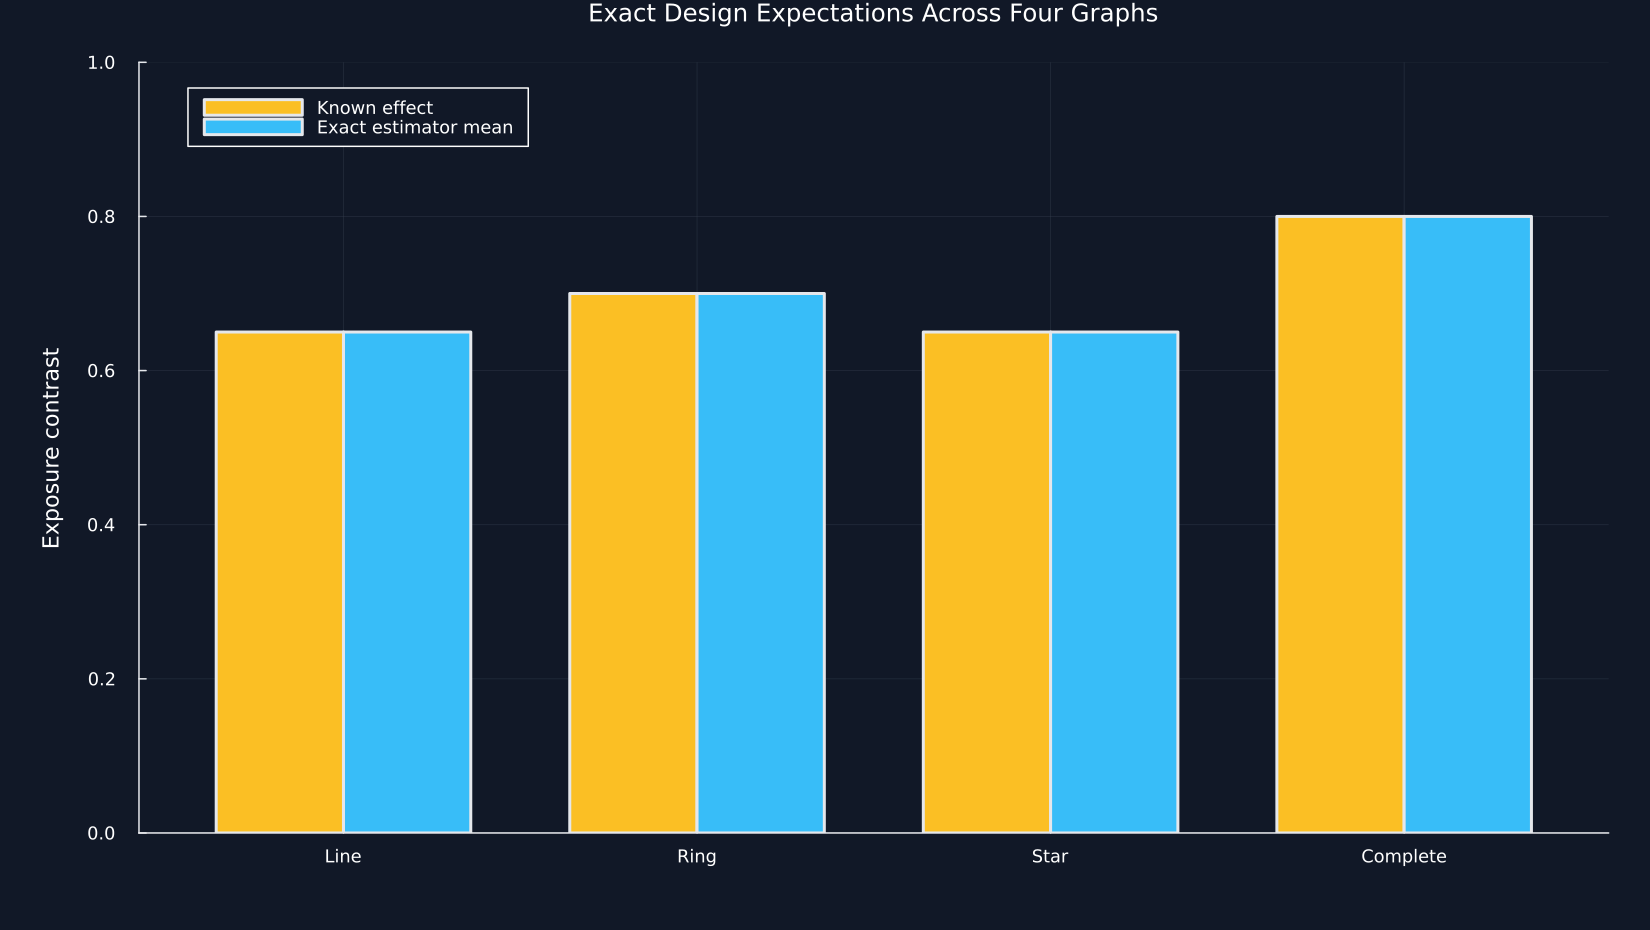

In [2]:
graph_builders=["Line"=>line_graph(4),"Ring"=>ring_graph(4),"Star"=>star_graph(4),"Complete"=>complete_graph(4)]
enumeration_probability=.35
graph_rows=[]
graph_estimate_rows=[]
for (graph_name,graph) in graph_builders
    graph_degrees=vec(sum(graph;dims=2))
    graph_probabilities=exposure_probabilities(graph,enumeration_probability)
    baseline=1 .+.2 .*collect(0:3)+.3 .*graph_degrees
    effects=.5 .+.1 .*graph_degrees
    expected_estimate=0.
    estimate_minimum=Inf
    estimate_maximum=-Inf
    for assignment in all_assignments(4)
        exposure=exposure_labels(graph,assignment)
        outcome=baseline+effects.*exposure
        estimate=exposure_result(outcome,exposure,graph_probabilities).contrast
        probability=assignment_probability(assignment,enumeration_probability)
        expected_estimate+=probability*estimate
        estimate_minimum=min(estimate_minimum,estimate)
        estimate_maximum=max(estimate_maximum,estimate)
        push!(graph_estimate_rows,(graph_name,join(assignment),probability,estimate))
    end
    graph_truth=mean(effects)
    push!(graph_rows,(graph_name,sum(graph)/2,minimum(graph_degrees),maximum(graph_degrees),graph_truth,expected_estimate,abs(expected_estimate-graph_truth),estimate_minimum,estimate_maximum))
end
graph_enumeration=frame(["Graph","Edges","Minimum degree","Maximum degree","Known average effect","Exact expected estimate","Absolute error","Minimum assignment estimate","Maximum assignment estimate"],graph_rows)
graph_estimates=frame(["Graph","Assignment","Assignment probability","Estimate"],graph_estimate_rows)
@assert all(isapprox.(graph_enumeration[:,5],graph_enumeration[:,6]))
table(graph_enumeration,"ht_graph_enumeration")
save_data(graph_estimates,paths,"ht_all_small_graph_assignments")
save_data(graph_enumeration,paths,"ht_graph_expectations")
figure=bar(collect(1:4).-.18,graph_enumeration[:,5];bar_width=.36,color=palette.amber,label="Known effect",xticks=(1:4,graph_enumeration.Graph),ylabel="Exposure contrast",title="Exact Design Expectations Across Four Graphs",ylims=(0,1.),size=(1100,620),legend=:topleft)
bar!(figure,collect(1:4).+.18,graph_enumeration[:,6];bar_width=.36,color=palette.cyan,label="Exact estimator mean")
save_figure(figure,paths,"ht_graph_expectations")


## A Controlled Experiment on the Public Topology

The public graph is now held fixed, but assignments and potential outcomes are generated. Unit $i$ has

$$
Y_i(0)=b_i,\qquad Y_i(1)=b_i+\tau_i,
$$

where $b_i$ is a fixed generated baseline and $\tau_i=0.4+0.1d_i$ is a declared exposure effect based on degree $d_i$. The known average effect is $N^{-1}\sum_i\tau_i$. This design tests the calculation; it does not turn the public correlations into causal evidence.

Row,Industry,Degree,Generated baseline,Generated exposure effect,Probability of exposure zero,Probability of exposure one
,String,Int64,Float64,Float64,Float64,Float64
1,Agric,2,0.81281,0.6,0.5625,0.4375
2,Food,3,1.43412,0.7,0.421875,0.578125
3,Soda,2,1.30358,0.6,0.5625,0.4375
4,Beer,4,1.60099,0.8,0.316406,0.683594
5,Smoke,2,1.12271,0.6,0.5625,0.4375
6,Toys,2,0.98064,0.6,0.5625,0.4375
7,Fun,2,1.56764,0.6,0.5625,0.4375
8,Books,3,1.38174,0.7,0.421875,0.578125
9,Hshld,3,1.2314,0.7,0.421875,0.578125


Row,Quantity,Value
,String,Real
1,Assignments enumerated,4096
2,Known average exposure effect,0.666667
3,Exact Horvitz-Thompson expectation,0.666667
4,Exact expectation error,1.11022e-16
5,Naive expectation when both groups appear,0.755826
6,Probability both exposure groups appear,0.949848


Row,Estimator,Mean,Standard deviation,Error from truth,Valid repetitions
,String,Float64,Float64,Float64,Int64
1,Horvitz-Thompson,0.675536,1.52289,0.00886921,5000
2,Naive observed difference,0.757438,0.162506,0.0907715,4756


Row,Estimator,5th percentile,Median,95th percentile,Minimum,Maximum
,String,Float64,Float64,Float64,Float64,Float64
1,Horvitz-Thompson contrast,-1.73119,0.83356,3.09917,-2.96718,3.81352
2,Naive observed difference,0.468904,0.752166,1.01359,0.33258,1.21787


Row,Industry,Exposure,Observed outcome,Unit contribution
,String,Int64,Float64,Float64
1,Agric,1,1.41281,3.22928
2,Food,0,1.43412,-3.39939
3,Soda,0,1.30358,-2.31748
4,Beer,1,2.40099,3.5123
5,Smoke,0,1.12271,-1.99592
6,Toys,1,1.58064,3.61289
7,Fun,1,2.16764,4.95461
8,Books,1,2.08174,3.60084
9,Hshld,1,1.9314,3.3408


Row,Check,Rejected,Explanation
,String,String,String
1,Exposure label outside the supplied columns,Pass,Stopped as required
2,Contrasted exposures are identical,Pass,Stopped as required
3,A contrasted exposure has zero probability,Pass,Stopped as required
4,Probability row exceeds one,Pass,Stopped as required


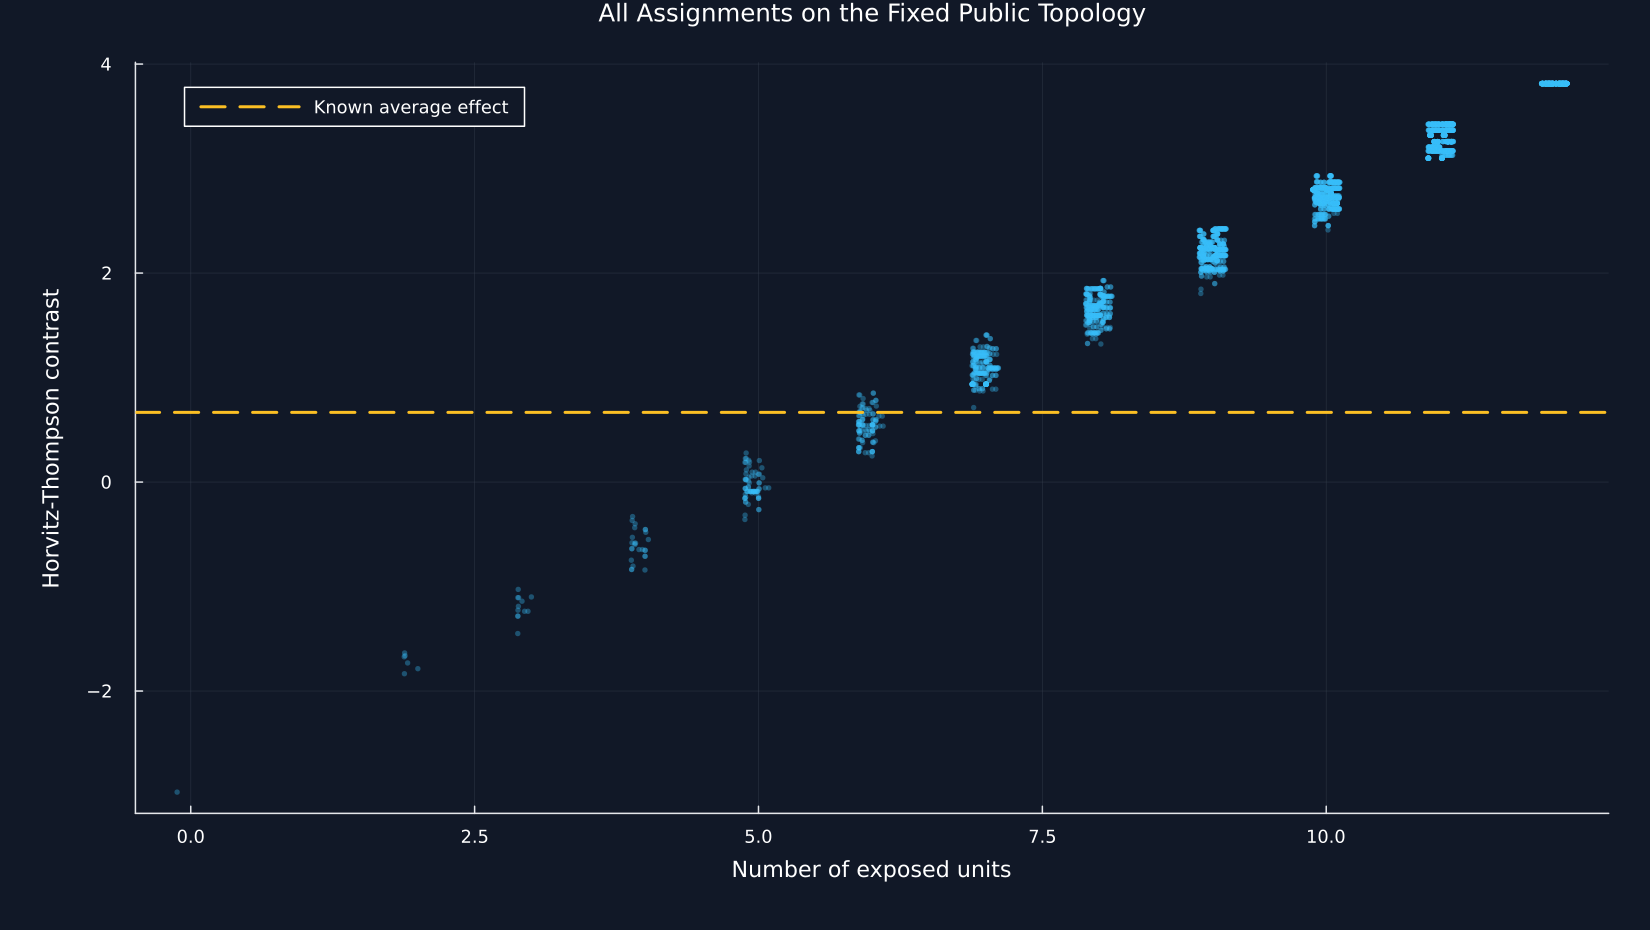

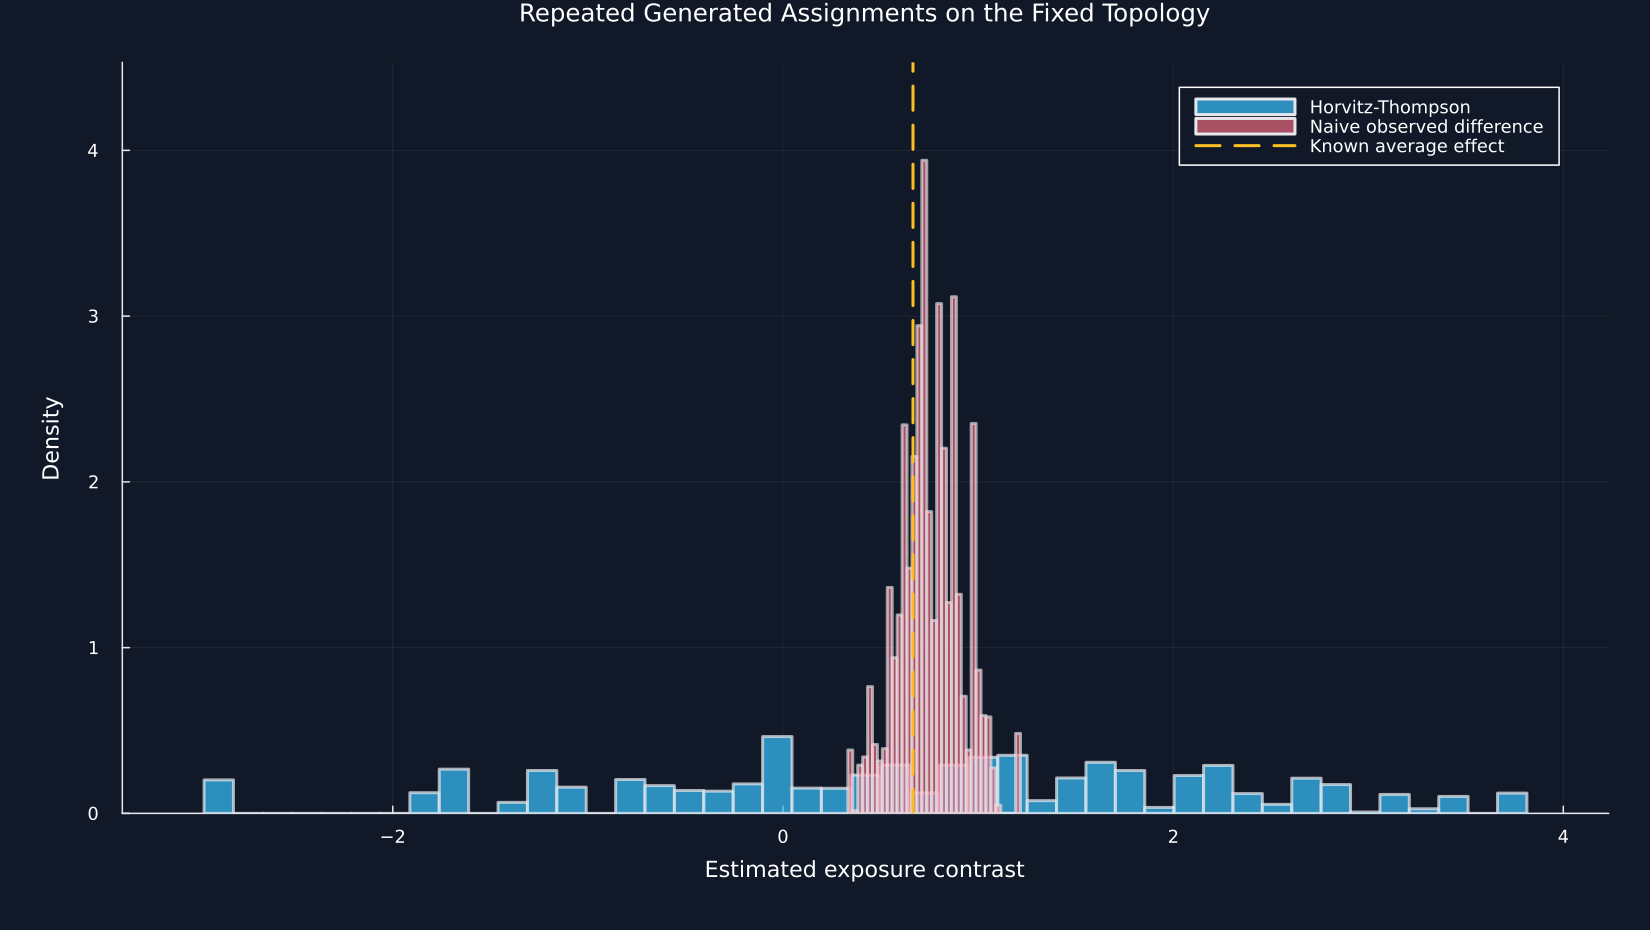

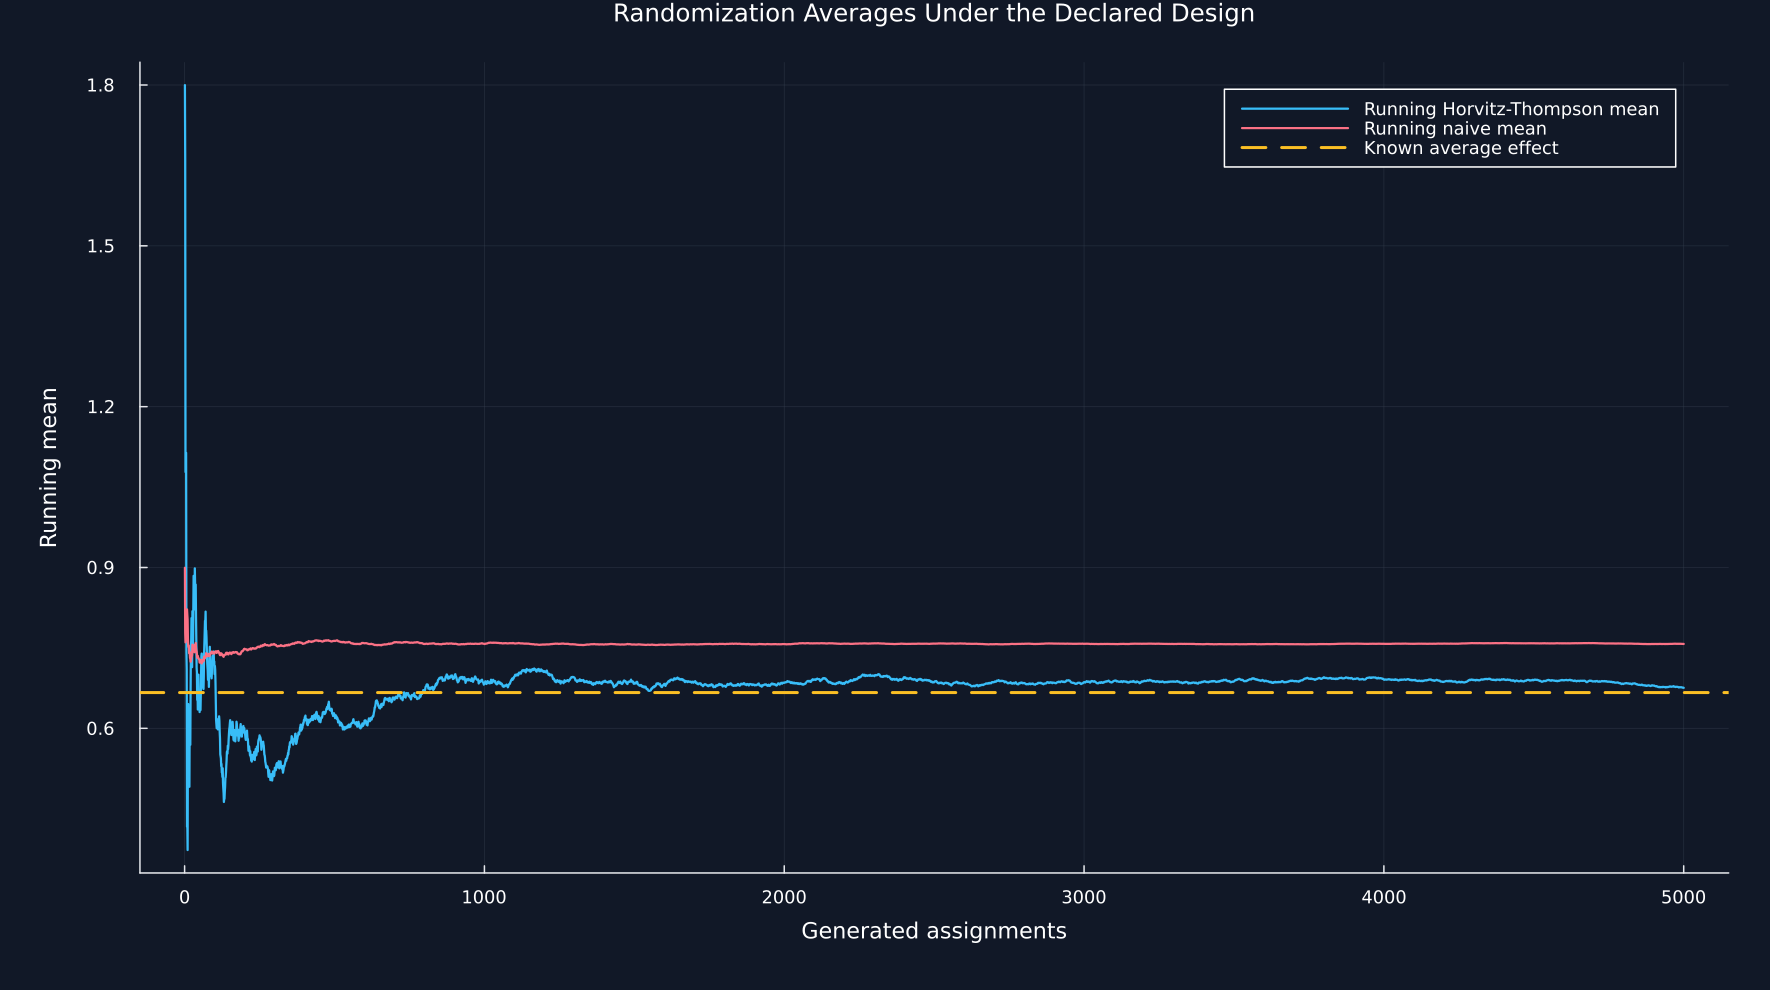

In [3]:
dates,all_industries,public_returns=network_returns()
selected_returns=public_returns[:,1:12]
industries=all_industries[1:12]
adjacency=correlation_graph(cor(selected_returns),2)
degrees=vec(sum(adjacency;dims=2))
public_probability=.25
public_probabilities=exposure_probabilities(adjacency,public_probability)
baseline=.5 .+.3 .*degrees+.2 .*vec(normal_block(store,"baseline"))
effects=.4 .+.1 .*degrees
known_effect=mean(effects)
generated_design=DataFrame("Industry"=>industries,"Degree"=>degrees,"Generated baseline"=>baseline,"Generated exposure effect"=>effects,"Probability of exposure zero"=>public_probabilities[:,1],"Probability of exposure one"=>public_probabilities[:,2])
table(generated_design,"ht_public_generated_design")
exact_rows=[]
for assignment in all_assignments(12)
    exposure=exposure_labels(adjacency,assignment)
    outcome=baseline+effects.*exposure
    result=exposure_result(outcome,exposure,public_probabilities)
    probability=assignment_probability(assignment,public_probability)
    naive=0<sum(exposure)<12 ? mean(outcome[exposure.==1])-mean(outcome[exposure.==0]) : NaN
    push!(exact_rows,(probability,sum(exposure),result.contrast,naive))
end
public_exact=frame(["Assignment probability","Exposed units","Horvitz-Thompson contrast","Naive observed difference"],exact_rows)
exact_ht_mean=sum(public_exact[:,1].*public_exact[:,3])
valid=isfinite.(public_exact[:,4])
valid_probability=sum(public_exact[valid,1])
exact_naive_mean=sum(public_exact[valid,1].*public_exact[valid,4])/valid_probability
@assert isapprox(exact_ht_mean,known_effect)
exact_summary=frame(["Quantity","Value"],[("Assignments enumerated",nrow(public_exact)),("Known average exposure effect",known_effect),("Exact Horvitz-Thompson expectation",exact_ht_mean),("Exact expectation error",exact_ht_mean-known_effect),("Naive expectation when both groups appear",exact_naive_mean),("Probability both exposure groups appear",valid_probability)])
table(exact_summary,"ht_public_exact_summary")
simulation_count=5000
public_assignments=normal_block(store,"public")
simulation=network_estimates(adjacency,baseline,effects,public_probability,public_assignments[1:simulation_count,:])
simulation[!,"Running Horvitz-Thompson mean"]=running_finite_mean(simulation[:,3])
simulation[!,"Running naive mean"]=running_finite_mean(simulation[:,4])
repeated_summary=frame(["Estimator","Mean","Standard deviation","Error from truth","Valid repetitions"],[(name,mean(values),std(values),mean(values)-known_effect,length(values)) for (name,column) in [("Horvitz-Thompson",3),("Naive observed difference",4)] for values in (filter(isfinite,simulation[:,column]),)])
table(repeated_summary,"ht_public_repeated_summary")
quantiles=frame(["Estimator","5th percentile","Median","95th percentile","Minimum","Maximum"],[(name,quantile(values,.05),median(values),quantile(values,.95),minimum(values),maximum(values)) for (name,column) in [("Horvitz-Thompson contrast",3),("Naive observed difference",4)] for values in (filter(isfinite,simulation[:,column]),)])
table(quantiles,"ht_public_quantiles")
first_assignment=Int.(public_assignments[end,:])
first_exposure=exposure_labels(adjacency,first_assignment)
first_outcome=baseline+effects.*first_exposure
first_result=exposure_result(first_outcome,first_exposure,public_probabilities)
example_contributions=DataFrame("Industry"=>industries,"Exposure"=>first_exposure,"Observed outcome"=>first_outcome,"Unit contribution"=>first_result.unit_contributions)
table(example_contributions,"ht_public_contributions")
invalid_checks=frame(["Check","Rejected","Explanation"],[network_failure("Exposure label outside the supplied columns",()->exposure_mean_contrast([1],[3],[.5 .5];first=1,second=2)),network_failure("Contrasted exposures are identical",()->exposure_mean_contrast([1],[1],[.5 .5];first=1,second=1)),network_failure("A contrasted exposure has zero probability",()->exposure_mean_contrast([1],[1],[1 0];first=1,second=2)),network_failure("Probability row exceeds one",()->exposure_mean_contrast([1],[1],[.6 .6];first=1,second=2))])
@assert all(invalid_checks.Rejected)
table(invalid_checks,"ht_invalid_input_checks")
save_data(public_exact,paths,"ht_public_exact_distribution")
figure=scatter(public_exact[:,2]+collect(range(-.12,.12;length=nrow(public_exact))),public_exact[:,3];color=palette.cyan,markersize=2,markerstrokewidth=0,alpha=.35,label="",xlabel="Number of exposed units",ylabel="Horvitz-Thompson contrast",title="All Assignments on the Fixed Public Topology",size=(1100,620))
hline!(figure,[known_effect];color=palette.amber,linewidth=2,linestyle=:dash,label="Known average effect")
save_figure(figure,paths,"ht_public_exact_distribution")
save_data(simulation,paths,"ht_public_repeated_estimates")
ht_values=simulation[:,3]
naive_values=filter(isfinite,simulation[:,4])
ht_histogram=network_histogram(ht_values,45)
naive_histogram=network_histogram(naive_values,35)
save_data(ht_histogram,paths,"ht_public_histogram_bins")
save_data(naive_histogram,paths,"ht_public_naive_histogram_bins")
figure=bar((ht_histogram[:,1]+ht_histogram[:,2])/2,ht_histogram.Density;bar_width=ht_histogram[:,2]-ht_histogram[:,1],color=palette.cyan,alpha=.72,label="Horvitz-Thompson",xlabel="Estimated exposure contrast",ylabel="Density",title="Repeated Generated Assignments on the Fixed Topology",size=(1100,620),ylims=(0,1.15max(maximum(ht_histogram.Density),maximum(naive_histogram.Density))))
bar!(figure,(naive_histogram[:,1]+naive_histogram[:,2])/2,naive_histogram.Density;bar_width=naive_histogram[:,2]-naive_histogram[:,1],color=palette.rose,alpha=.65,label="Naive observed difference")
vline!(figure,[known_effect];color=palette.amber,linewidth=2,linestyle=:dash,label="Known average effect")
save_figure(figure,paths,"ht_public_repeated_estimates")
figure=plot(simulation.Repetition,simulation[:,5];color=palette.cyan,linewidth=1.5,label="Running Horvitz-Thompson mean",xlabel="Generated assignments",ylabel="Running mean",title="Randomization Averages Under the Declared Design",size=(1180,660))
plot!(figure,simulation.Repetition,simulation[:,6];color=palette.rose,linewidth=1.5,label="Running naive mean")
hline!(figure,[known_effect];color=palette.amber,linewidth=2,linestyle=:dash,label="Known average effect")
save_figure(figure,paths,"ht_public_running_means")
